# ML Week 3 - K-Means Clustering
##### Today we will build our very first Machine Learning algorithm from scratch!
##### We will be building an unsupervised algorithm called "K-means". It is useful for identifying patterns in messy tabular data by "clustering" rows that seem to have similar properties. As it is unsupervised, we don't have to worry about labelling data beforehand.

### Datset
Today we will build a very "toy" version of K-means, and therefore use a super simplistic dataset. This is a made-up dataset of stone tool measurements (the values are from the super famous "Iris" Dataset - a dataset of different types of Iris flowers containing measurements of the pedals).

Next week we will apply K-means to a real architecture dataset

### How it works:

<div>
<img src="Kmeans.png" width="1500"/>
</div>

## Importing Common Packages
##### Always a good place to start

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Read in our dataset

In [2]:
# download tool data and read it into a dataframe
df = pd.read_csv("./tools.csv")

In [3]:
df

,Length,Width,Thickness,SharpEdgeWidth,Culture
0,5.1,3.5,1.4,0.2,Bear Culture
1,4.9,3.0,1.4,0.2,Bear Culture
2,4.7,3.2,1.3,0.2,Bear Culture
3,4.6,3.1,1.5,0.2,Bear Culture
4,5.0,3.6,1.4,0.2,Bear Culture
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Beaver Culture
146,6.3,2.5,5.0,1.9,Beaver Culture
147,6.5,3.0,5.2,2.0,Beaver Culture
148,6.2,3.4,5.4,2.3,Beaver Culture


In [4]:
# The last column ("Culture") contains the name of the culture for each row. This is kinda the answer.
# Let's remove it for now and see if we can identify the different cultures ourselves. Using it would kinda be cheating

X = df[["Length", "Width", "Thickness", "SharpEdgeWidth"]]
y = df['Culture']

# Cleaner way:
# X = df.iloc[:,:-1]
# y = df.iloc[:,-1]

In [5]:
X.head()

,Length,Width,Thickness,SharpEdgeWidth
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


<Axes: xlabel='Length', ylabel='Width'>

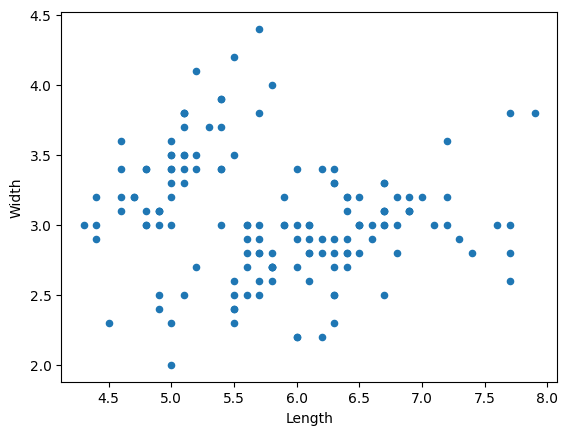

In [6]:
X.plot.scatter(x = 'Length', y='Width')

In [7]:
# Depending on ML application it is sometimes better to use a numpy array vs a DataFrame.
# Here we now only have numeric data, and we don't really care about the meanings of the columns beyond this point
# So this is a good time to use a numpy array - it's cleaner and we can manipulate it more easily.
X = X.to_numpy()

In [8]:
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

## A quick intro to NumPy Arrays

In [9]:
# For a 2D numpy array you can get a specific item like this:
# 12th row, 2nd column:
X[11,1] # (Remember the indices start from 0)

# we can get rows or columns like this:
# First row:
X[0,:]
# Last row:
X[-1,:]
# First column:
X[:,1]
# Last column:
X[:,-1]

# You can also choose only specific rows, similar to with dataframes
X[X[:,1] < 1]

# Or return all values that satisfy the condition
X[X < 1]

array([0.2, 0.2, 0.2, 0.2, 0.2, 0.4, 0.3, 0.2, 0.2, 0.1, 0.2, 0.2, 0.1,
       0.1, 0.2, 0.4, 0.4, 0.3, 0.3, 0.3, 0.2, 0.4, 0.2, 0.5, 0.2, 0.2,
       0.4, 0.2, 0.2, 0.2, 0.2, 0.4, 0.1, 0.2, 0.1, 0.2, 0.2, 0.1, 0.2,
       0.2, 0.3, 0.3, 0.2, 0.6, 0.4, 0.3, 0.2, 0.2, 0.2, 0.2])

In [10]:
# Let's chceck the shape of our data.
# We see we have 150 points, each with 4 "features". These are like points in some big "4D" space
X.shape

(150, 4)

## Randomly select K points
##### Here we will set K=3. Later we will study how to choose the best K value

In [11]:
# We need to randomly select 3 points to set as cluster centres
# This command randomly shuffles the rows
randomized_X = np.random.permutation(X)

In [12]:
# Now we can just pick the first 3 rows from our shuffled array
centroids = randomized_X[:3]

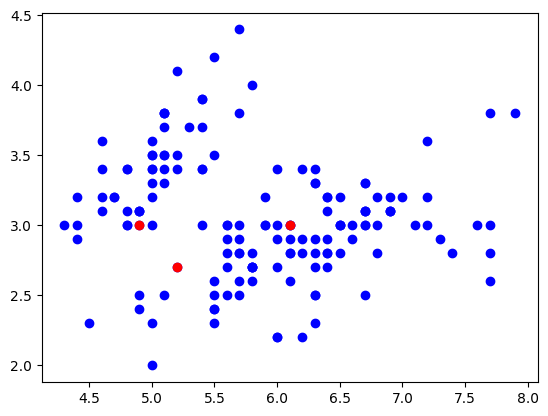

In [13]:
# We can see the 3 random points we have selected
plt.scatter(x = X[:,0], y = X[:,1], c='blue')
plt.scatter(x = centroids[:,0], y = centroids[:,1], c='red')

## For each point, we now check which centroid it's closest to
##### We can do this using the numpy linalg.norm function

In [14]:

points = np.array((), dtype=np.int8)
for i in range(len(X)):
    distance_1 = np.linalg.norm((X[i] - centroids[0]))
    distance_2 = np.linalg.norm((X[i] - centroids[1]))
    distance_3 = np.linalg.norm((X[i] - centroids[2]))
    cluster = np.argmin([distance_1, distance_2, distance_3])  # This finds the cluster for the point "i" based on which of the 3 distances is closer
    points = np.append(points, cluster)

# A more efficient way of doing this:
#for i in range(len(X)):
#    cluster = np.argmin(np.linalg.norm((X[i] - centroids), axis=1))
#    points = np.append(points, cluster)

In [15]:
points

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

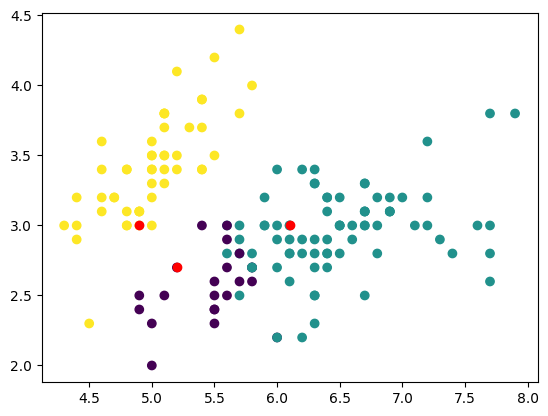

In [16]:
plt.scatter(x = X[:,0], y = X[:,1], c=points)
plt.scatter(x = centroids[:,0], y = centroids[:,1], c='red')

## Define new centroids as the centres (means) of each cluster
##### That's why it's called k-means! O_O

In [17]:
# This is actually quite easy to do
# X[points==i] takes only the rows of X which are attributed to cluster "i". Then we just average these with ".mean"
for i in range(3):
    centroids[i] = X[points==i].mean(axis=0)

In [18]:
# And now we have new centroids!
centroids

array([[5.46363636, 2.55909091, 3.87727273, 1.19545455],
       [6.48717949, 2.96025641, 5.19615385, 1.81153846],
       [5.006     , 3.418     , 1.464     , 0.244     ]])

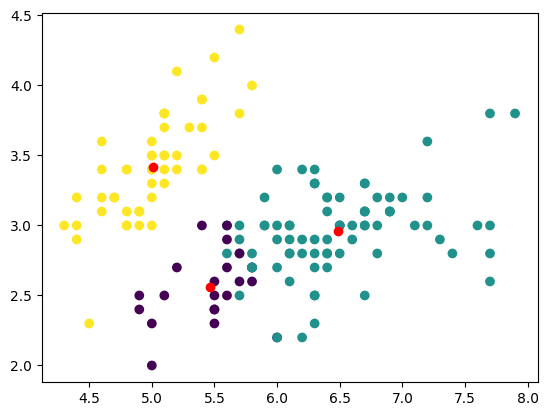

In [19]:
# We can see the centroids moving to the centre of the clusters:

plt.scatter(x = X[:,0], y = X[:,1], c=points)
plt.scatter(x = centroids[:,0], y = centroids[:,1], c='red')

## Taking all of this and putting it into a K-means function

In [20]:
def kmeans(X:np.array, K:int=3, iterations:int=100) -> np.array:
    """
    This implements the Kmeans clustering algorithm
    Parametres:
    X: Data on which to apply kmeans
    K: Number of clusters
    iterations: How many times to iterate before returning the clusters
    """

    # We first randomly choose K points to be centroids
    randomized_X = np.random.permutation(X)
    centroids = randomized_X[:K]

    # Now we iterate the specified number of times
    for _ in range(iterations):
        points = np.array((), dtype=np.int8)
        # Find which centroid each point is closest to (put it in the "points" array)
        for i in range(len(X)):
            cluster = np.argmin(np.linalg.norm((X[i] - centroids), axis=1))
            points = np.append(points, cluster)
        # Update the centroids to be in the middle of each cluster (mean value of all points in each cluster)
        for i in range(K):
            centroids[i] = X[points==i].mean(axis=0)
    return np.column_stack((X,points)) # This attaches the cluster guesses to the main data

In [42]:
# We can now run kmeans and save it to a "pred" array
pred = kmeans(X,3,100)

In [43]:
# The last column is the guess for each tool
pred

array([[5.1, 3.5, 1.4, 0.2, 1. ],
       [4.9, 3. , 1.4, 0.2, 1. ],
       [4.7, 3.2, 1.3, 0.2, 1. ],
       [4.6, 3.1, 1.5, 0.2, 1. ],
       [5. , 3.6, 1.4, 0.2, 1. ],
       [5.4, 3.9, 1.7, 0.4, 1. ],
       [4.6, 3.4, 1.4, 0.3, 1. ],
       [5. , 3.4, 1.5, 0.2, 1. ],
       [4.4, 2.9, 1.4, 0.2, 1. ],
       [4.9, 3.1, 1.5, 0.1, 1. ],
       [5.4, 3.7, 1.5, 0.2, 1. ],
       [4.8, 3.4, 1.6, 0.2, 1. ],
       [4.8, 3. , 1.4, 0.1, 1. ],
       [4.3, 3. , 1.1, 0.1, 1. ],
       [5.8, 4. , 1.2, 0.2, 1. ],
       [5.7, 4.4, 1.5, 0.4, 1. ],
       [5.4, 3.9, 1.3, 0.4, 1. ],
       [5.1, 3.5, 1.4, 0.3, 1. ],
       [5.7, 3.8, 1.7, 0.3, 1. ],
       [5.1, 3.8, 1.5, 0.3, 1. ],
       [5.4, 3.4, 1.7, 0.2, 1. ],
       [5.1, 3.7, 1.5, 0.4, 1. ],
       [4.6, 3.6, 1. , 0.2, 1. ],
       [5.1, 3.3, 1.7, 0.5, 1. ],
       [4.8, 3.4, 1.9, 0.2, 1. ],
       [5. , 3. , 1.6, 0.2, 1. ],
       [5. , 3.4, 1.6, 0.4, 1. ],
       [5.2, 3.5, 1.5, 0.2, 1. ],
       [5.2, 3.4, 1.4, 0.2, 1. ],
       [4.7, 3

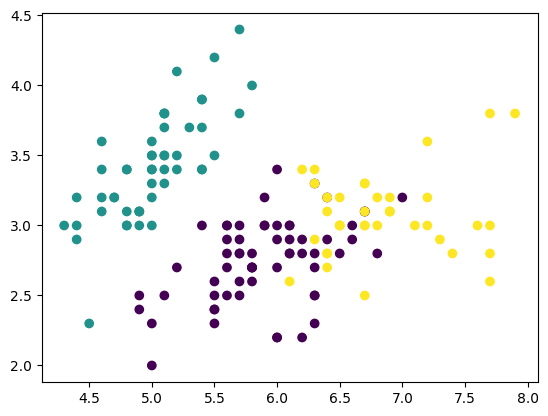

In [46]:
plt.scatter(x = X[:,0], y = X[:,1], c=pred[:,-1])

In [24]:
for i in range(len(y)):
    print(y[i], ", ", int(pred[:,-1][i]))

Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  1
Bear Culture ,  2
Bear Culture ,  1
Owl Culture ,  0
Owl Culture ,  0
Owl Culture ,  0
Owl Culture ,  0
Owl Culture ,  0
Owl Culture ,  

## Let's see how this could have been done with sklearn pre-packaged k-means

In [25]:
# Import the package
from sklearn.cluster import KMeans

In [38]:
# Initialize Kmeans and fit it to our data
kmeans2 = KMeans(n_clusters=3, max_iter=100).fit(X)


In [39]:
# Let's save the labels as a new list of predictions
pred2 = kmeans2.labels_

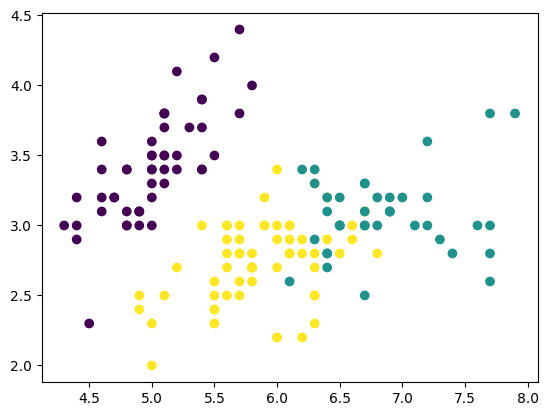

In [40]:
# We can see we arrive at something quite similar to what we coded ourselves.
plt.scatter(x = X[:,0], y = X[:,1], c=pred2[:])

In [29]:
# Now if we have the measurements of a new tool, we can predict which culture it is likely from using the predict method
new_tool = np.array([[1, 1, 5, 1]]) # Note the double sqare brackets. This is because we can esimte
kmeans2.predict(new_tool)

array([0], dtype=int32)

# Exercises

### Exercise 1
K-means is an unsupervised algorithm, which means we generally don't have a way to "test" its performance. However, in our case we do have labels, so we may be curious to see how it has performed. In this exercise we will work through this.

#### Exercise 1.1
Remembe in python you can use the equality operator "==" to do this: array[some indexes] == some number
This returns a long list of when the array is equal to some value (You get a bunch of True/False booleans)
With this in mind, see when the last column of pred (the predicted labels) are equal to zero.

In [ ]:
pred[:,-1] == 0

#### Exercise 1.2
Now, remember the "y" variable contains the labels for each culture. Index the y with square brackets, and in the square brackets put the equality expression from the previous exercise. This gives a long list of the labels which have been associated to cluster "0". Ideally we want to have every data point in the cluster represent the same label, but of course in reality that is not likely.

In [52]:
y[pred[:,-1] == 0]

50        Owl Culture
51        Owl Culture
53        Owl Culture
54        Owl Culture
55        Owl Culture
            ...      
133    Beaver Culture
138    Beaver Culture
142    Beaver Culture
146    Beaver Culture
149    Beaver Culture
Name: Culture, Length: 62, dtype: object

#### Exercise 1.3

Remember last week we had the Counter function from the collections library? Save the output of the previous step to some variable, and then put that in the Counter function. We assume that the most common label is the "correct" label for cluster 0 (and any other labels are points that have been put into the incorrect cluster).

In [54]:
from collections import Counter

cultures = y[pred[:,-1] == 0]
culture_count = Counter(cultures)
culture_count

Counter({'Owl Culture': 48, 'Beaver Culture': 14})

#### Exercise 1.4

If we want to count how many cultures are correctly placed in cluster 0:

* Use the .values() method on the result that comes out of the Counter function
* Turn this into a list
* Apply the "max" function to retun the number of "correct points"

In [55]:
max(list(culture_count.values()))

48

#### Exercise 1.5

Now we can put all of this together to see the "accuracy" of our clustering.

Put the code from the above exercises into a for loop and loop over each cluster. For each loop, add the maximum values of the Counter (for cluster "i") to some dummy variable which will add up the total "correct" points for all clusters. Finally, divide this value by the length of "y" (the total number of points) and multiply by 100. There's the accuracy!

Note: Each time you rerun the kmeans funciton, the random shuffling results in a new set of predictions (pred). Then the accuracy will be different. You can try it.

In [44]:
from collections import Counter

correctly_classified = 0

for i in range(3):
    culture = y[pred[:,-1] == i]  # Return the culture labels corresponding to the rows clustered together for each cluster # (ie. 0,1,2)
    culture_count = Counter(culture)  # We can use Counter to see which labels ended up in which cluster
    print(culture_count)  # The most common label in each cluster IS the label for that cluster
    correctly_classified += max(list(culture_count.values()))  # If we add the most common labels for each cluster, these are the ones successfully put into the right cluster. The less common labels are in the wrong cluster

print("The clustering successfully grouped " + str(correctly_classified/len(y)*100) + "% of the data.")


Counter({'Owl Culture': 48, 'Beaver Culture': 14})
Counter({'Bear Culture': 50})
Counter({'Beaver Culture': 36, 'Owl Culture': 2})
The clustering successfully grouped 89.33333333333333% of the data.


### Exercise 2
KMeans has lots of arguments. Explore some of them:
https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

init and n_init, for example. Also set verbose to True so you can see what happens as the algorithm is fit to the data

In [31]:
# Not really much to do here except checking the documentation online and turning on verbose

KMeans(n_clusters=3, max_iter=100, verbose=True).fit(X)

Initialization complete
Iteration 0, inertia 110.65.
Iteration 1, inertia 79.06260032983428.
Iteration 2, inertia 78.94084142614602.
Converged at iteration 2: strict convergence.


,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,100
,tol,0.0001
,verbose,True
,random_state,None
,copy_x,True
,algorithm,'lloyd'
